# 01 · Exploratory analysis

IBM Telco Customer Churn: 7,043 customers, one row each, with the services they have, how they pay and whether they left.
The goal here is to understand what drives churn before modeling, and to decide which features and segments are worth tracking later.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110

from churn import config
from churn.data.ingest import load_clean
from churn.models.evaluate import add_segments

df = add_segments(load_clean())
print(df.shape)
print(f"churn rate: {df[config.TARGET].mean():.1%}")
df.head()

(7043, 22)
churn rate: 26.5%


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,tenure_band
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-6m
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48m
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-6m
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48m
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-6m


## Data quality

The only missing values are 11 blank `TotalCharges`, and all of them are customers with `tenure = 0`: they just joined and haven't been billed.
That's not an error, so I keep the rows and let the pipeline impute them. The validation schema allows up to 2% nulls in that column.

In [2]:
print(df.isna().sum()[lambda s: s > 0])
df.loc[df["total_charges"].isna(), ["tenure", "monthly_charges", "total_charges"]].head()

total_charges    11
dtype: int64


,tenure,monthly_charges,total_charges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN


## Churn by segment

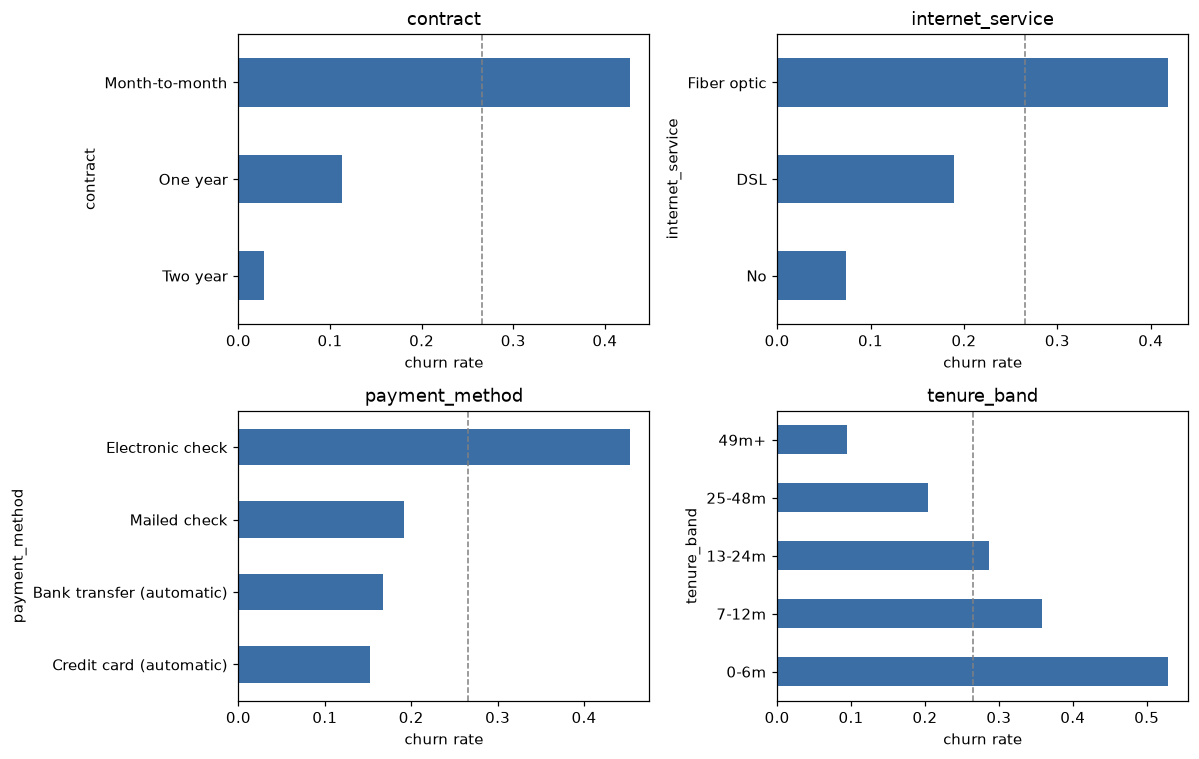

In [3]:
segments = ["contract", "internet_service", "payment_method", "tenure_band"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, segments):
    order = config.TENURE_LABELS if col == "tenure_band" else None
    rates = df.groupby(col)[config.TARGET].mean()
    rates = rates.reindex(order) if order else rates.sort_values()
    rates.plot.barh(ax=ax, color="#3b6ea5")
    ax.axvline(df[config.TARGET].mean(), color="grey", ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlabel("churn rate")
fig.tight_layout()

In [4]:
pd.concat(
    {col: df.groupby(col)[config.TARGET].agg(churn_rate="mean", customers="size") for col in segments}
)

churn_rate  customers
contract         Month-to-month                  0.427       3875
                 One year                        0.113       1473
                 Two year                        0.028       1695
internet_service DSL                             0.190       2421
                 Fiber optic                     0.419       3096
                 No                              0.074       1526
payment_method   Bank transfer (automatic)       0.167       1544
                 Credit card (automatic)         0.152       1522
                 Electronic check                0.453       2365
                 Mailed check                    0.191       1612
tenure_band      0-6m                            0.529       1481
                 13-24m                          0.287       1024
                 25-48m                          0.204       1594
                 49m+                            0.095       2239
                 7-12m                           0.359        705

What stands out:

- **Contract is the biggest separator.** Month-to-month churns at 42.7%, one-year at 11.3% and two-year at 2.8%. 88.6% of all churners are on month-to-month.
- **Tenure matters almost as much.** 52.9% of customers in their first six months leave, against 9.5% after four years.
- **Fiber (41.9%) and electronic check (45.3%)** are the other high-risk groups.

This is why I monitor performance by contract and tenure band, not only globally. A model can look fine overall and still be weak inside a segment.
It's also why the simulated drift biases cohorts toward month-to-month, fiber and electronic-check customers: that's the realistic way this base would change after an aggressive acquisition campaign.

## Numeric features

,tenure,monthly_charges
churn,,
0,38.0,64.425
1,10.0,79.650


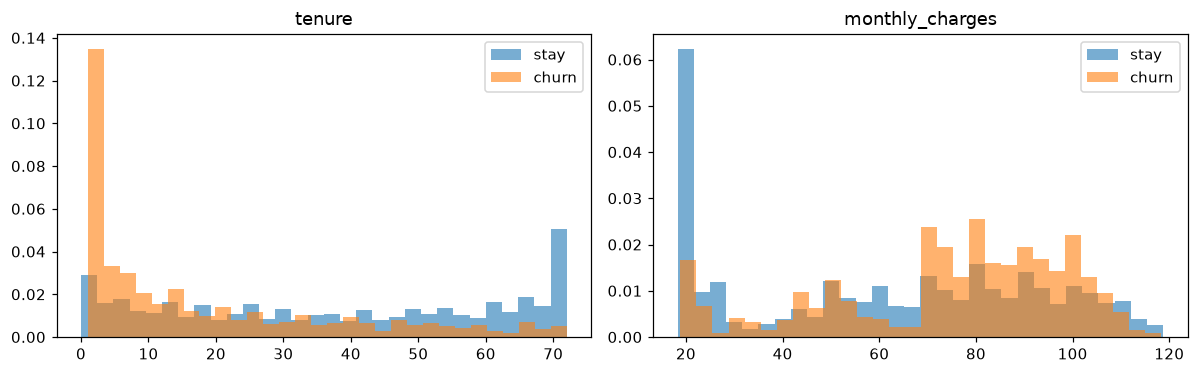

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["tenure", "monthly_charges"]):
    for label, part in df.groupby(config.TARGET):
        ax.hist(part[col], bins=30, alpha=0.6, density=True, label="churn" if label else "stay")
    ax.set_title(col)
    ax.legend()
fig.tight_layout()
df.groupby(config.TARGET)[["tenure", "monthly_charges"]].median()

Churners are much newer (median tenure 10 months vs 38) and pay more per month (79.65 vs 64.43).

corr(total_charges, tenure x monthly_charges) = 0.9996


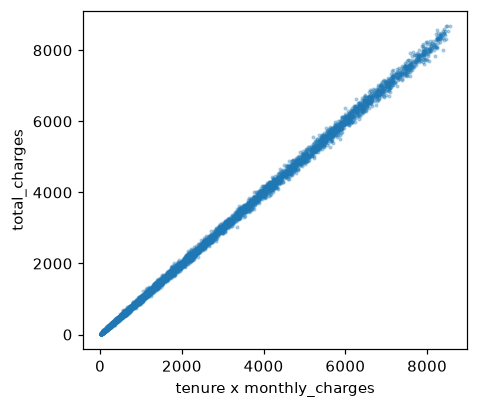

In [6]:
clean = df.dropna(subset=["total_charges"])
implied = clean["tenure"] * clean["monthly_charges"]
print(f"corr(total_charges, tenure x monthly_charges) = {clean['total_charges'].corr(implied):.4f}")
plt.figure(figsize=(4.5, 4))
plt.scatter(implied, clean["total_charges"], s=3, alpha=0.3)
plt.xlabel("tenure x monthly_charges")
plt.ylabel("total_charges");

`total_charges` is almost exactly `tenure x monthly_charges` (correlation 0.9996), so on its own it adds little.
Two consequences:

1. I add `avg_monthly_spend = total_charges / tenure`. Where it differs from the current monthly charge, it captures a plan change, which is real signal.
2. In the stress test, shifting `total_charges` alone creates customers that can't exist. The model card flags that result instead of reading it as a scenario.

## Takeaways for modeling

- 26.5% positives: imbalanced but not extreme. I use Gini/KS and recall on the business decision, never accuracy.
- Strong categorical drivers, so logistic regression is a serious baseline next to tree models.
- Segment-level monitoring for contract and tenure band.
- The decision has to be priced. Who to contact depends on what the customer is worth, not just on the probability.